# Forest Cover Type – Exploratory Data Analysis


### Dataset Overview

This dataset is used to predict forest cover types from cartographic variables. The full description of the features and target classes can be found in the **`data/covtype.info`** file. The target variable is `Cover_Type`, which contains 7 different forest cover categories.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
train = pd.read_csv('../data/train.csv')
print(train.shape)
train.head()

(50120, 55)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


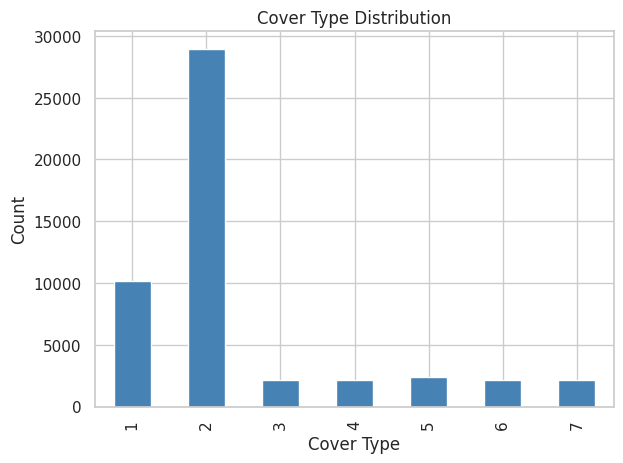

In [2]:
# Target distribution
train['Cover_Type'].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Cover Type Distribution')
plt.xlabel('Cover Type'); plt.ylabel('Count')
plt.tight_layout(); plt.show()

In [3]:
# Missing values
print('Missing values:', train.isnull().sum().sum())

Missing values: 0


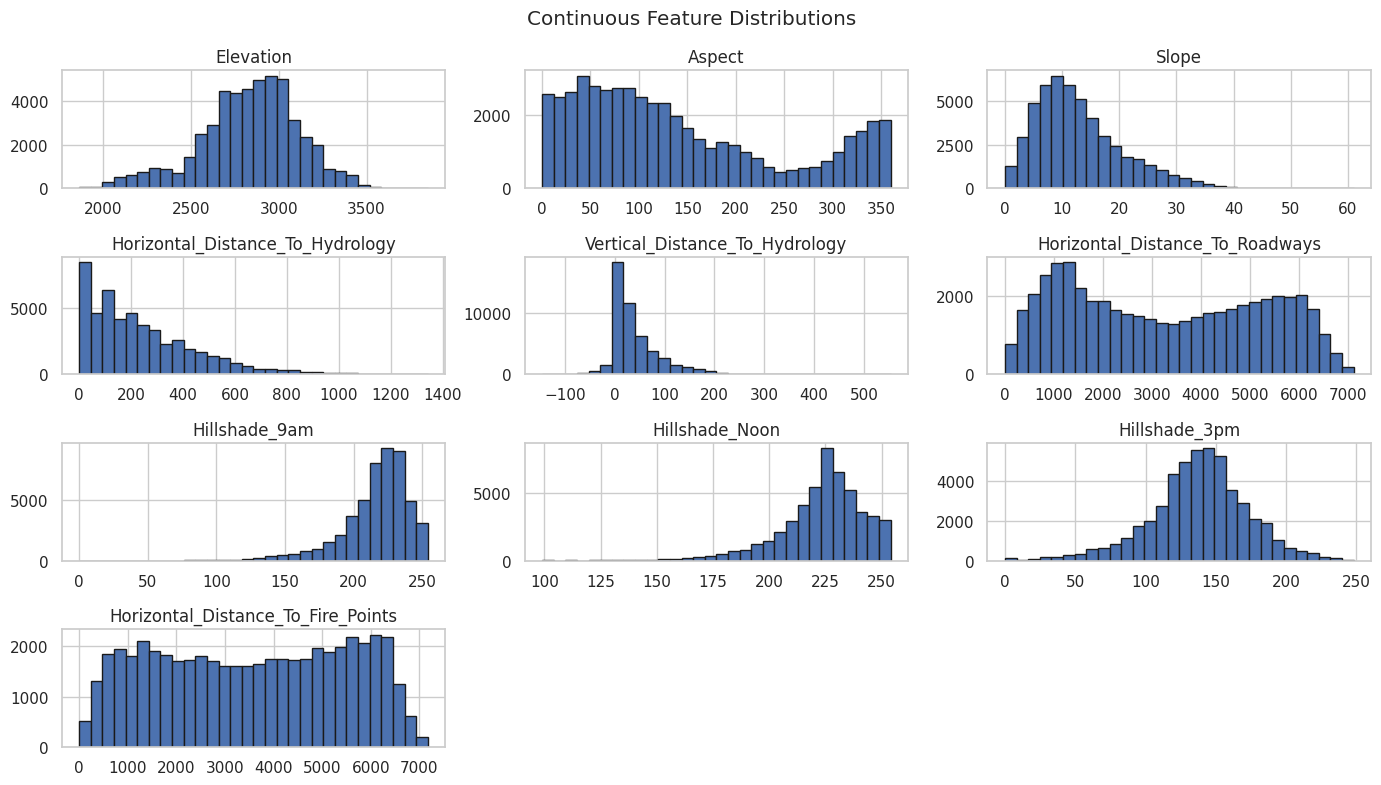

In [4]:
# Continuous feature distributions
cont_cols = ['Elevation','Aspect','Slope',
             'Horizontal_Distance_To_Hydrology','Vertical_Distance_To_Hydrology',
             'Horizontal_Distance_To_Roadways','Hillshade_9am','Hillshade_Noon',
             'Hillshade_3pm','Horizontal_Distance_To_Fire_Points']
train[cont_cols].hist(figsize=(14, 8), bins=30, edgecolor='k')
plt.suptitle('Continuous Feature Distributions')
plt.tight_layout(); plt.show()

In [5]:
# Engineered features preview
import sys; sys.path.insert(0, '../scripts')
from preprocessing_feature_engineering import engineer_features

train_eng = engineer_features(train)
new_feats = ['Distance_To_Hydrology','Fire_Road_Difference',
             'Mean_Hillshade','Elev_Hydro_Interaction','High_Elevation_Flag']
train_eng[new_feats + ['Cover_Type']].describe()

,Distance_To_Hydrology,Fire_Road_Difference,Mean_Hillshade,Elev_Hydro_Interaction,High_Elevation_Flag,Cover_Type
count,50120.000000,50120.000000,50120.000000,5.012000e+04,50120.000000,50120.000000
mean,247.461022,284.511872,192.698650,7.246701e+05,0.283579,2.459138
std,209.239908,2486.099760,13.706204,6.553603e+05,0.450740,1.551823
min,0.000000,-6012.000000,102.666667,0.000000e+00,0.000000,1.000000
25%,87.097646,-1651.000000,186.666667,2.394420e+05,0.000000,2.000000
50%,194.644548,183.000000,195.333333,5.462210e+05,0.000000,2.000000
75%,360.873593,2270.000000,201.666667,1.024111e+06,1.000000,2.000000
max,1356.939571,6017.000000,213.666667,4.639055e+06,1.000000,7.000000
